## Лабораторная работа №1 | Вариант 5

Выполнил: 

### 1. Numpy

In [1]:
import numpy as np

1. Создайте единичную матрицу размером 3х3

In [2]:
np.eye(3, dtype=int)

array([[1, 0, 0],
       [0, 1, 0],
       [0, 0, 1]])

2. Создайте кастомный dtype который описывает цвет состоящий из 4х unsigned bytes(RGBA пиксель)

In [3]:
rgba = np.dtype([("R", "u1"), ("G", "u1"), ("B", "u1"), ("A", "u1")])
np.array([(255, 0, 0, 255)], dtype=rgba)

array([(255, 0, 0, 255)],
      dtype=[('R', 'u1'), ('G', 'u1'), ('B', 'u1'), ('A', 'u1')])

3. Как игнорировать все numpy warnings(не рекомендуем к использованию)?

In [4]:
with np.errstate(all="ignore"):
    print(np.array([1.0, 0.0]) / 0)

[inf nan]


4. Создайте случайный вектор размера 10 и отсортируйте его

In [5]:
vector = np.random.random(10)
vector.sort()
vector

array([0.06972609, 0.20415124, 0.25427026, 0.26133161, 0.270373  ,
       0.45301208, 0.52314304, 0.59727768, 0.77850387, 0.80506543])

5. Создайте read-only массив(неизменяемый)

In [6]:
array = np.arange(5)
array.flags.writeable = False
array

array([0, 1, 2, 3, 4])

6. Рассмотрим случайную матрицу размером 10х2, представляющую декартовы координаты, преобразуем их в полярные координаты

In [7]:
coordinates = np.random.random((10, 2))
x, y = coordinates.T
np.column_stack((np.hypot(x, y), np.arctan2(y, x)))

array([[0.93492085, 1.31142112],
       [0.52332797, 0.84037772],
       [0.5769365 , 0.55224021],
       [0.58060037, 0.5080014 ],
       [0.58340885, 0.70333609],
       [0.36829758, 0.53768687],
       [0.88011936, 0.63478127],
       [0.94956445, 1.29953379],
       [0.97153289, 0.45770253],
       [0.35523213, 1.45152843]])

7. Создайте структурированный массив с координатами x и y, охватывающий область [0,1]x[0,1]

In [8]:
x, y = np.meshgrid(np.linspace(0, 1, 5), np.linspace(0, 1, 5))
grid = np.zeros((5, 5), dtype=[("x", float), ("y", float)])
grid["x"] = x
grid["y"] = y
grid

array([[(0.  , 0.  ), (0.25, 0.  ), (0.5 , 0.  ), (0.75, 0.  ),
        (1.  , 0.  )],
       [(0.  , 0.25), (0.25, 0.25), (0.5 , 0.25), (0.75, 0.25),
        (1.  , 0.25)],
       [(0.  , 0.5 ), (0.25, 0.5 ), (0.5 , 0.5 ), (0.75, 0.5 ),
        (1.  , 0.5 )],
       [(0.  , 0.75), (0.25, 0.75), (0.5 , 0.75), (0.75, 0.75),
        (1.  , 0.75)],
       [(0.  , 1.  ), (0.25, 1.  ), (0.5 , 1.  ), (0.75, 1.  ),
        (1.  , 1.  )]], dtype=[('x', '<f8'), ('y', '<f8')])

8. Учитывая два массива X и Y, постройте матрицу Коши $C$ ($C_{ij} =\frac{1}{x_i - y_j}$)

In [9]:
x = np.random.normal(size=5)
y = np.random.normal(size=5)
1 / (x[:, None] - y[None, :])

array([[  2.70714392,   0.53358015,   6.35478372,   0.61979746,
         -1.41267563],
       [ -0.63622611, -14.91901365,  -0.56060113,  -3.05128339,
         -0.37749555],
       [ -0.47420452,  -1.65547831,  -0.43088108,  -1.15639366,
         -0.31386686],
       [ -0.48255813,  -1.76196084,  -0.43776696,  -1.20736217,
         -0.31750479],
       [ -0.38687235,  -0.92584684,  -0.35754341,  -0.74582637,
         -0.27306725]])

9. Как конвертировать массив float(32 bit) к массиву целых чисел (integer 32 bit) in place?

In [10]:
floats = np.array([1.9, -2.7, 0.0, 3.2], dtype=np.float32)
integers = floats.view(np.int32)
integers[:] = floats
integers

array([ 1, -2,  0,  3], dtype=int32)

10. Как случайно заменить p элементов в 2D массиве?

In [11]:
matrix = np.arange(1, 21).reshape(4, 5)
p = 6
indices = np.random.choice(matrix.size, p, replace=False)
matrix.flat[indices] = 0
matrix

array([[ 1,  2,  0,  4,  0],
       [ 0,  7,  8,  0, 10],
       [11,  0,  0, 14, 15],
       [16, 17, 18, 19, 20]])

### 2. Pandas

Найдите ответы на вопросы или выполните действия с предложенным датасетом 

Классический начальный набор данных - данные пассажиров титаника.

Файл: `data.csv`

```
PassangerId - уникальный номер пассажира
Survived - выжил человек или нет
Pclass - класс обслуживания
Name - имя человека, обращение к ней/нему
Sex - пол человека
Age - возраст на момент крушения
SibSp - количество братьев и сестер / супругов на борту "Титаника"
Parch - количество родителей / детей на борту "Титаника"
Ticket - номер билета
Fare - стоимость проезда для пассажиров
Cabin - каюта
Embarked - причал отбытия. C = Cherbourg Q = Queenstown S = Southampton
```

In [12]:
import pandas as pd

In [13]:
df = pd.read_csv("data.csv")

1. Узнайте сколько было на борту человек

In [14]:
len(df)

891

2. Какой медианный и средний возраста пассажиров

In [15]:
print("Медианный возраст:", df["Age"].median())
print("Средний возраст:", df["Age"].mean())

Медианный возраст: 28.0
Средний возраст: 29.69911764705882


3. Посчитайте процент выживаемости детей(до 16 лет) и взрослых

In [16]:
children = df[df["Age"] < 16]
adults = df[df["Age"] >= 16]
print("Дети, %:", children["Survived"].mean() * 100)
print("Взрослые, %:", adults["Survived"].mean() * 100)

Дети, %: 59.036144578313255
Взрослые, %: 38.193343898573694


4. Верна ли гипотеза, что женщины и дети сажались в шлюпки первыми и выживали больше?

In [17]:
survival = pd.Series({
    "Мужчины от 16 лет": adults[adults["Sex"] == "male"]["Survived"].mean() * 100,
    "Женщины от 16 лет": adults[adults["Sex"] == "female"]["Survived"].mean() * 100,
    "Дети до 16 лет": children["Survived"].mean() * 100
})
print(survival)
print("Женщины и дети выживали чаще мужчин. Порядок посадки в данных не указан.")

Мужчины от 16 лет    17.433414
Женщины от 16 лет    77.522936
Дети до 16 лет       59.036145
dtype: float64
Женщины и дети выживали чаще мужчин. Порядок посадки в данных не указан.


5. Зависит ли выживаемость от класса обслуживания?

In [18]:
print(df.groupby("Pclass")["Survived"].mean() * 100)
print("Чем выше класс обслуживания, тем выше выживаемость.")

Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64
Чем выше класс обслуживания, тем выше выживаемость.


6. Посчитайте средний возраст умерших женщин и мужчин

In [19]:
df[df["Survived"] == 0].groupby("Sex")["Age"].mean()

Sex
female    25.046875
male      31.618056
Name: Age, dtype: float64

7. Различается ли процент выживаемости пассажиров с хотя бы одним родственником на борту и одиночек?

In [20]:
with_family = df[df["SibSp"] + df["Parch"] > 0]
alone = df[df["SibSp"] + df["Parch"] == 0]
print("С родственниками, %:", with_family["Survived"].mean() * 100)
print("Одиночки, %:", alone["Survived"].mean() * 100)
print("С родственниками выживали чаще.")

С родственниками, %: 50.56497175141242
Одиночки, %: 30.353817504655495
С родственниками выживали чаще.


8. Различается ли средняя стоимость билета у умерших и выживших пассажиров?

In [21]:
print(df.groupby("Survived")["Fare"].mean())
print("У выживших средняя стоимость билета выше.")

Survived
0    22.117887
1    48.395408
Name: Fare, dtype: float64
У выживших средняя стоимость билета выше.


9. Выведите максимальный и минимальный возраст выживших пассажиров во 2 классе обслуживания

In [22]:
df[(df["Survived"] == 1) & (df["Pclass"] == 2)]["Age"].agg(["min", "max"])

min     0.67
max    62.00
Name: Age, dtype: float64

10. Подтвердите или опровергните гипотезу: молодым мужчинам(от 18 лет) выжить легче, чем более взрослым

In [23]:
men = df[df["Sex"] == "male"]
print("18–29 лет, %:", men[(men["Age"] >= 18) & (men["Age"] < 30)]["Survived"].mean() * 100)
print("30 лет и старше, %:", men[men["Age"] >= 30]["Survived"].mean() * 100)
print("Гипотеза не подтверждается: мужчины от 30 лет выживали чаще.")

18–29 лет, %: 15.64245810055866
30 лет и старше, %: 19.444444444444446
Гипотеза не подтверждается: мужчины от 30 лет выживали чаще.


### 3. Визуализация

Используя библиотеки matplotlib/sns/plotly/pandas и набор данных представленный ранее визуализируйте

1. Постройте гистограмму распределения возростов пассажиров

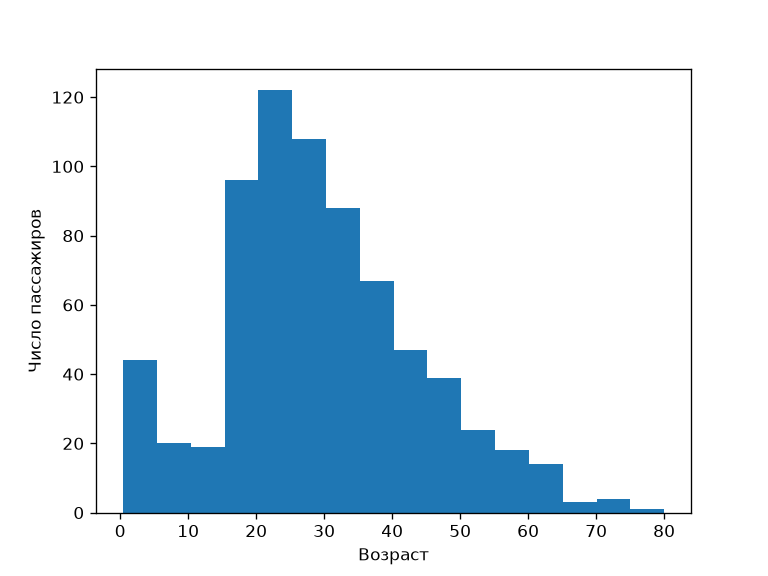

In [24]:
import matplotlib.pyplot as plt

plt.hist(df["Age"].dropna(), bins=16)
plt.xlabel("Возраст")
plt.ylabel("Число пассажиров")
plt.show()

2. Постройте гистограммы распределения цен для пассажиров разных классов

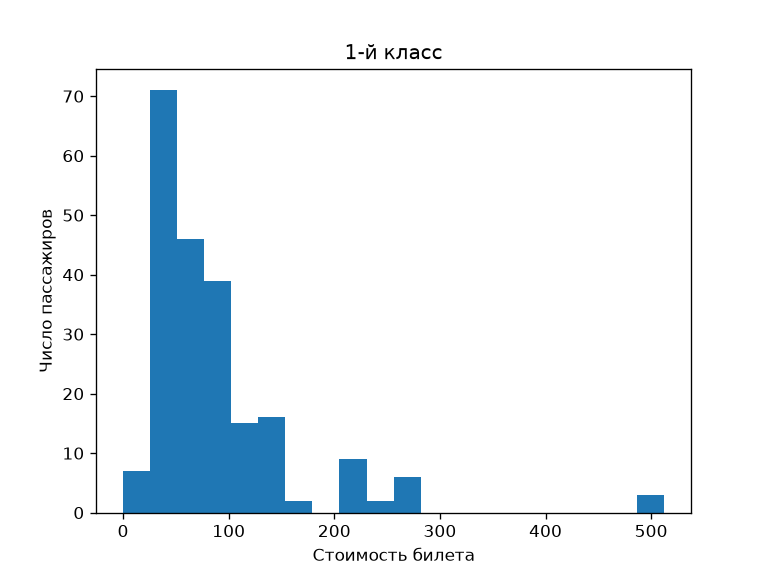

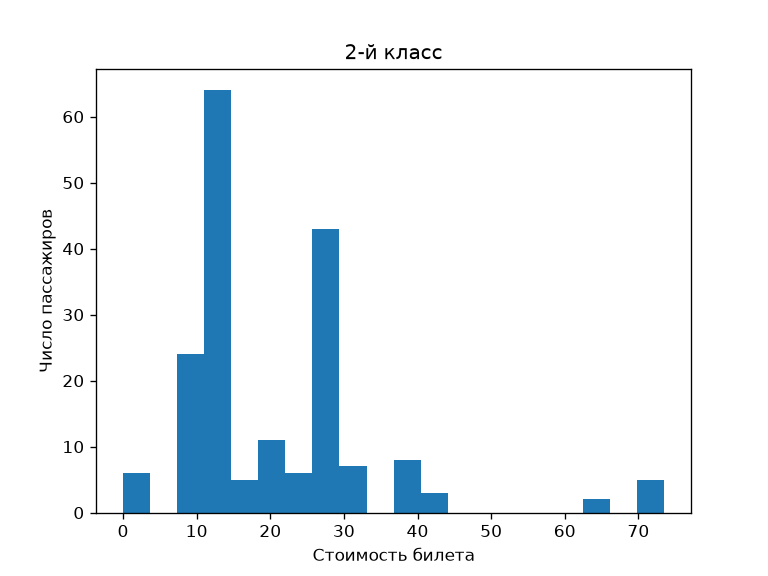

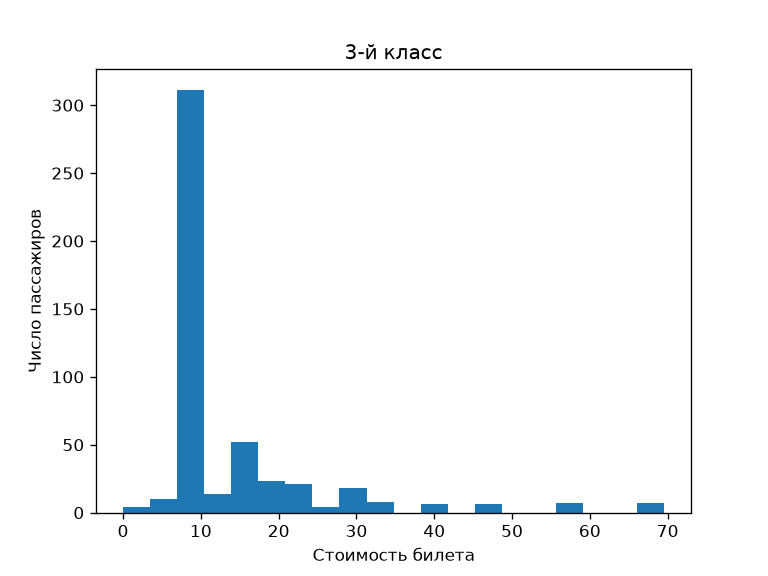

In [25]:
for passenger_class in [1, 2, 3]:
    plt.hist(df[df["Pclass"] == passenger_class]["Fare"], bins=20)
    plt.title(f"{passenger_class}-й класс")
    plt.xlabel("Стоимость билета")
    plt.ylabel("Число пассажиров")
    plt.show()

3. Постройте зависимость цены от возраста пассажира

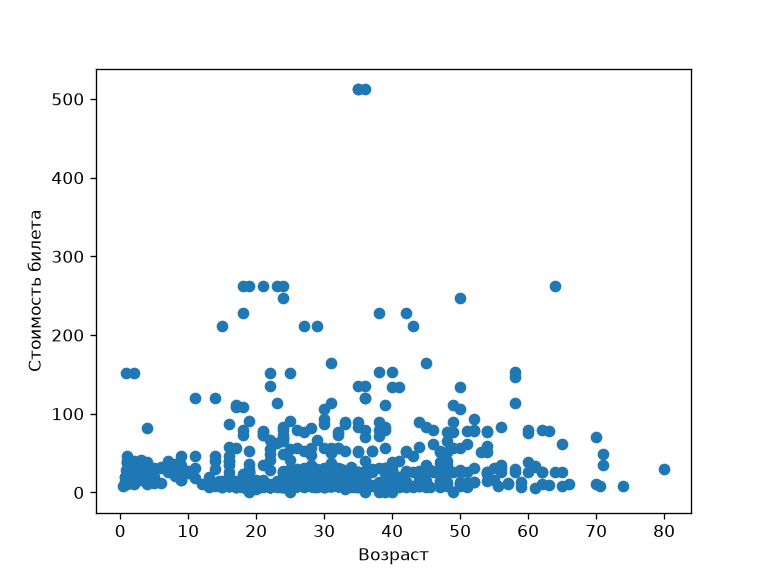

In [26]:
plt.scatter(df["Age"], df["Fare"])
plt.xlabel("Возраст")
plt.ylabel("Стоимость билета")
plt.show()

4. Постройте box plot отображающий распределение цен на билеты в разных классах

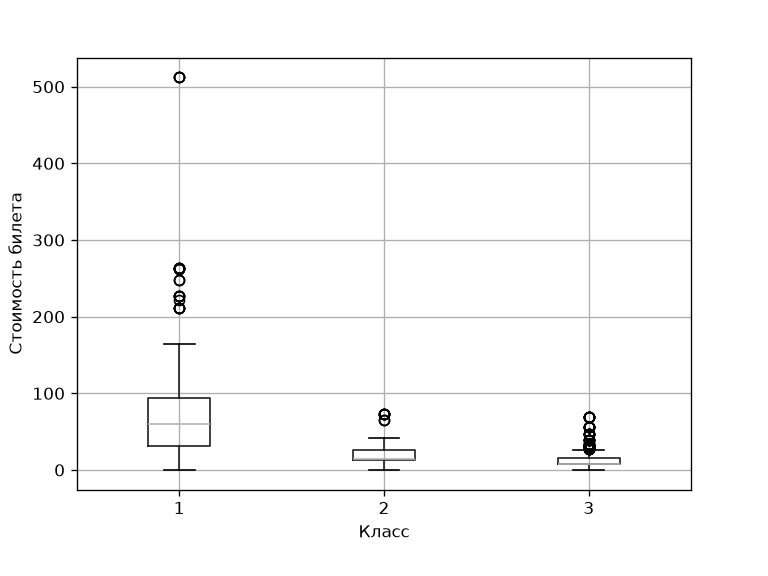

In [27]:
df.boxplot(column="Fare", by="Pclass")
plt.xlabel("Класс")
plt.ylabel("Стоимость билета")
plt.title("")
plt.suptitle("")
plt.show()

5. Визуализируйте распределение долей выживших среди мужчин, женщин и детей(до 16 лет)

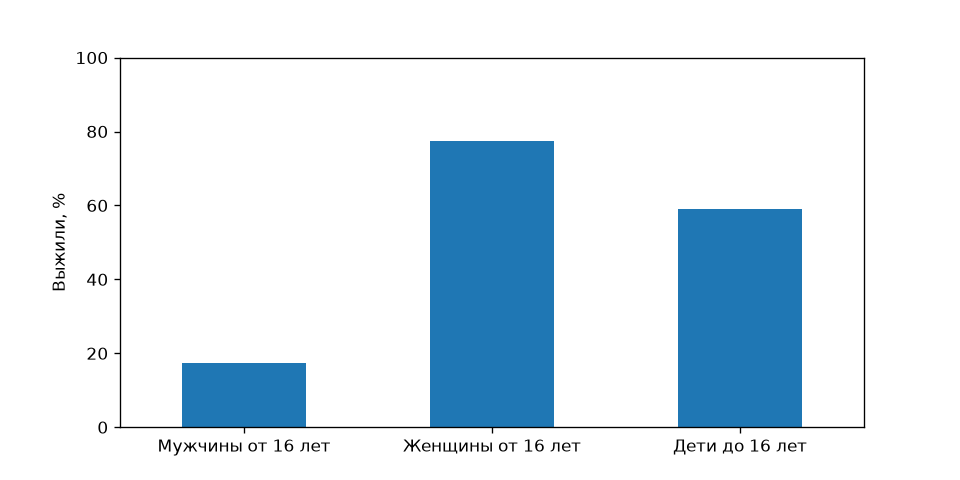

In [28]:
survival.plot.bar(rot=0, figsize=(8, 4))
plt.ylabel("Выжили, %")
plt.ylim(0, 100)
plt.show()

6. Сравните плотности распределения возростов выживших и умерших пассажиров, сделайте выводы

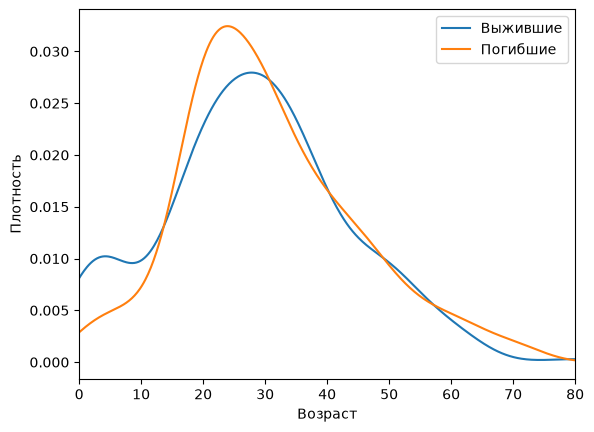

Распределения похожи. Среди выживших доля детей выше.


In [32]:
df[df["Survived"] == 1]["Age"].plot.kde(label="Выжившие")
df[df["Survived"] == 0]["Age"].plot.kde(label="Погибшие")
plt.xlabel("Возраст")
plt.ylabel("Плотность")
plt.xlim(0, 80)
plt.legend()
plt.show()
print("Распределения похожи. Среди выживших доля детей выше.")

7. Постройте круговую диаграмму отображающую выживаемость мужчин и женщин в разных классах обслуживания(визуализация должна быть интуитивно понятная без объяснений, женщины и мужчины соответствующих классов объеденены визуально в одну группу и 2 подгруппы)*

\* Задание на доп. балл